In [1]:
import torch
from torch.distributions.multivariate_normal import MultivariateNormal
import math
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
from torch import nn
import torch.optim as optim
import torch.nn.functional as F



In [2]:
T_final = 30.0
dt = 0.01
N_T = int(T_final/dt+1)
t = torch.linspace(0.0,T_final,N_T)

In [6]:
a_1 = 1.0+0.15*torch.cos(0.08*t)
a_2 = 0.3+0.05*torch.sin(0.04*t)

omega_1 = 2*torch.pi*(1.2+0.08*torch.sin(0.03*t))
omega_2 = 2*torch.pi*(0.25+0.02*torch.cos(0.02*t))

theta_1 = 2*torch.pi*(1.2*t-0.08/0.03*torch.cos(0.03*t)+0.08/0.03)
theta_2 = 2*torch.pi*(0.25*t+torch.sin(0.02*t))


noise_sigma = 0.1
mvn = MultivariateNormal(torch.zeros(N_T),noise_sigma**2*torch.eye(N_T))
noise = mvn.sample()

def y_1(s):
    
    waveform_1 = torch.cos(s)+0.45*torch.cos(2*s)-0.2*torch.sin(2*s)
    #waveform_1 = torch.cos(s)

    
    return waveform_1

def y_2(s):
    
    waveform_2 = torch.cos(s)+0.2*torch.sin(2*s)
    #waveform_2 = torch.cos(s)

    
    return waveform_2

v_1 = a_1*y_1(theta_1)
v_2 = a_2*y_2(theta_2)


v_noiseless = v_1+v_2
v = v_noiseless+noise

In [141]:
def Gabor(t,tau,omega,theta,alpha):
    #g = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau)+theta)
    g = torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau)+theta)

    return g

sample_rate_tau = 100
tau = t[::sample_rate_tau]
sample_size_tau = len(tau)

omega_min = 0.1*2*torch.pi
omega_max = 3*2*torch.pi
sample_size_omega = 100

omega = torch.linspace(omega_min, omega_max, sample_size_omega)
alpha = 25

sample_size_theta = 64
theta = torch.linspace(-torch.pi,torch.pi-torch.pi/sample_size_theta,sample_size_theta)

In [142]:
K = torch.zeros(N_T,N_T)

for i in range(len(tau)):
    for j in range(sample_size_omega):
        for k in range(sample_size_theta):
            chi = Gabor(t,tau[i],omega[j],theta[k],alpha)
            K += torch.outer(chi,chi)
            
nugget = 10**-5
Kv = torch.linalg.solve(K+nugget*torch.eye(N_T),v)

In [143]:

n_tau = len(tau)
n_omega = len(omega)

tau_grid_2d, omega_grid_2d = torch.meshgrid(tau, omega, indexing="ij")   # (n_tau, n_omega)

tau_ext = tau_grid_2d.reshape(-1, 1)      # (P,1)
omega_ext = omega_grid_2d.reshape(-1, 1)  # (P,1)

dt_grid = t[None, :] - tau_ext            # (P, N)

# same Gaussian envelope you are already using
#gauss = ((2 / torch.pi**3) ** 0.25) * torch.sqrt(omega_ext / alpha) * torch.exp(-((omega_ext * dt_grid / alpha) ** 2))
gauss = torch.exp(-((omega_ext * dt_grid / alpha) ** 2))
phase0 = omega_ext * dt_grid

g_cos = gauss * torch.cos(phase0)   # (P, N)
g_sin = gauss * torch.sin(phase0)   # (P, N)

A_flat = g_cos @ Kv   # (P,)
B_flat = g_sin @ Kv   # (P,)

A = A_flat.reshape(n_tau, n_omega)
B = B_flat.reshape(n_tau, n_omega)

I = torch.eye(N_T, dtype=t.dtype, device=t.device)
K_reg = K + nugget * I

# solve K x = g^T for all atoms at once
# g_cos, g_sin are (P, N_T)

Kg_cos = torch.linalg.solve(K_reg, g_cos.T).T   # (P, N_T)
Kg_sin = torch.linalg.solve(K_reg, g_sin.T).T   # (P, N_T)

N_cos = torch.sum(g_cos * Kg_cos, dim=1)        # (P,)
N_sin = torch.sum(g_sin * Kg_sin, dim=1)        # (P,)
N_avg = 0.5 * (N_cos + N_sin)

E_norm_flat = (A_flat**2 + B_flat**2) / (N_avg + 1e-12)
E_norm = E_norm_flat.reshape(n_tau, n_omega)

theta_e = torch.atan2(-B, A)        # shape: (n_tau, n_omega)
E_tau_omega = A**2 + B**2        

In [144]:
def unwrap_phase(x, dim=0, period=2*math.pi):
    dx = torch.diff(x, dim=dim)
    half = period / 2
    dx_wrapped = (dx + half) % period - half

    correction = dx_wrapped - dx
    correction = torch.where(torch.abs(dx) < half, torch.zeros_like(correction), correction)

    cumsum = torch.cumsum(correction, dim=dim)

    pad_shape = list(x.shape)
    pad_shape[dim] = 1
    pad = torch.zeros(pad_shape, dtype=x.dtype, device=x.device)

    correction_full = torch.cat([pad, cumsum], dim=dim)
    return x + correction_full

theta_e_unwrapped = unwrap_phase(theta_e, dim=0)

def smooth_along_tau(x, win=5):
    # x shape: (n_tau, n_omega)
    pad = win // 2
    xT = x.T.unsqueeze(1)  # (n_omega, 1, n_tau)
    kernel = torch.ones(1, 1, win, device=x.device, dtype=x.dtype) / win
    x_pad = torch.nn.functional.pad(xT, (pad, pad), mode="replicate")
    y = torch.nn.functional.conv1d(x_pad, kernel)
    return y.squeeze(1).T

theta_e_smooth = smooth_along_tau(theta_e_unwrapped, win=5)

w_e = torch.zeros_like(theta_e_smooth)

# nonuniform-safe finite differences
w_e[0] = (theta_e_smooth[1] - theta_e_smooth[0]) / (tau[1] - tau[0])
w_e[-1] = (theta_e_smooth[-1] - theta_e_smooth[-2]) / (tau[-1] - tau[-2])

tau_diff = (tau[2:] - tau[:-2]).unsqueeze(1)   # (n_tau-2,1)
w_e[1:-1] = (theta_e_smooth[2:] - theta_e_smooth[:-2]) / tau_diff

nearest_idx = torch.argmin(
    torch.abs(w_e[..., None] - omega[None, None, :]),
    dim=2
)  # shape: (n_tau, n_omega)

S = torch.full_like(E_tau_omega, float("-inf"))

# scatter max along omega-axis
S.scatter_reduce_(
    dim=1,
    index=nearest_idx,
    src=E_tau_omega,
    reduce="amax",
    include_self=True
)

S[S == float("-inf")] = 0.0

In [145]:
ridge_idx = torch.zeros((n_tau, 2), dtype=torch.long)

for i in range(n_tau):
    vals = S[i].clone()

    j1 = torch.argmax(vals)
    ridge_idx[i, 0] = j1

    band = 3
    left = max(0, j1 - band)
    right = min(n_omega, j1 + band + 1)
    vals[left:right] = -float("inf")

    j2 = torch.argmax(vals)
    ridge_idx[i, 1] = j2

ridge_idx, _ = torch.sort(ridge_idx, dim=1)
omega_ridges = omega[ridge_idx]

In [146]:
def Gabor_cos(t,tau,omega,alpha):
    #g_cos = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau))
    g_cos =torch.exp(-((t-tau)*omega/alpha)**2)*torch.cos(omega*(t-tau))

    return g_cos

def Gabor_sin(t,tau,omega,alpha):
    #g_sin = (2/torch.pi)**(1/4)*torch.sqrt(omega/alpha)*torch.exp(-((t-tau)*omega/alpha)**2)*torch.sin(omega*(t-tau))
    g_sin =torch.exp(-((t-tau)*omega/alpha)**2)*torch.sin(omega*(t-tau))

    return g_sin

In [147]:

n_tau, n_omega = S.shape

ridge_idx = torch.zeros((n_tau, 2), dtype=torch.long)

# ---------- helpers ----------

def smooth_ridges(x, win=7):
    """
    x: (n_tau, 2)
    smooth each ridge along tau
    """
    xT = x.T.unsqueeze(1)  # (2,1,n_tau)
    pad = win // 2
    kernel = torch.ones(1, 1, win, dtype=x.dtype, device=x.device) / win
    x_pad = F.pad(xT, (pad, pad), mode="replicate")
    y = F.conv1d(x_pad, kernel)
    return y.squeeze(1).T  # (n_tau, 2)


def build_soft_weights(S, omega, omega_ridges, ridge_win=7, sigma_bins=3.0,
                       quantile_keep=0.7, conf_sharpness=10.0):
    """
    Returns:
        w1_soft, w2_soft: (n_tau, n_omega)
        A1_mask, A2_mask: hard visualization masks only
        omega_ridges_smooth: smoothed ridges
    """
    # smooth ridge trajectories first
    omega_ridges_smooth = smooth_ridges(omega_ridges, win=ridge_win)

    # distances from each omega-bin to each ridge
    dist1 = torch.abs(omega[None, :] - omega_ridges_smooth[:, 0:1])   # (n_tau, n_omega)
    dist2 = torch.abs(omega[None, :] - omega_ridges_smooth[:, 1:2])   # (n_tau, n_omega)

    # softness scale in omega
    domega = omega[1] - omega[0]
    sigma_assign = sigma_bins * domega
    beta = 1.0 / (2.0 * sigma_assign**2)

    score1 = torch.exp(-beta * dist1**2)
    score2 = torch.exp(-beta * dist2**2)

    p1 = score1 / (score1 + score2 + 1e-12)
    p2 = 1.0 - p1

    # confidence from S so weak cells contribute less
    threshold = torch.quantile(S.reshape(-1), quantile_keep)
    sharpness = conf_sharpness / (threshold + 1e-12)
    conf = torch.sigmoid(sharpness * (S - threshold))

    w1_soft = conf * p1
    w2_soft = conf * p2

    # normalize so w1_soft + w2_soft = conf
    norm = w1_soft + w2_soft + 1e-12
    w1_soft = conf * w1_soft / norm
    w2_soft = conf * w2_soft / norm

    # only for visualization / debugging
    A1_mask = w1_soft > w2_soft
    A2_mask = w2_soft >= w1_soft

    return w1_soft, w2_soft, A1_mask, A2_mask, omega_ridges_smooth


def build_mode_kernels_soft(t, tau, omega, alpha, w1_soft, w2_soft,
                            eps_weight=1e-4):
    """
    Build K_1, K_2 using soft weights over (tau, omega).
    """
    N_T = len(t)
    K_1 = torch.zeros(N_T, N_T, dtype=t.dtype, device=t.device)
    K_2 = torch.zeros(N_T, N_T, dtype=t.dtype, device=t.device)

    tau_2d, omega_2d = torch.meshgrid(tau, omega, indexing="ij")
    params_2d = torch.stack([tau_2d.reshape(-1), omega_2d.reshape(-1)], dim=1)

    w1_flat = w1_soft.reshape(-1)
    w2_flat = w2_soft.reshape(-1)

    for idx in range(len(params_2d)):
        tau_val = params_2d[idx, 0]
        omega_val = params_2d[idx, 1]

        weight1 = w1_flat[idx]
        weight2 = w2_flat[idx]

        if (weight1 < eps_weight) and (weight2 < eps_weight):
            continue

        g_cos = Gabor_cos(t, tau_val, omega_val, alpha)
        g_sin = Gabor_sin(t, tau_val, omega_val, alpha)

        K_local = torch.outer(g_cos, g_cos) + torch.outer(g_sin, g_sin)

        if weight1 >= eps_weight:
            K_1 += weight1 * K_local

        if weight2 >= eps_weight:
            K_2 += weight2 * K_local

    return K_1, K_2


def recover_modes_from_soft_kernels(v, K_1, K_2, noise_sigma):
    """
    Recover w_1, w_2 from K_1, K_2.
    """
    N_T = len(v)
    I = torch.eye(N_T, dtype=v.dtype, device=v.device)

    K_full = K_1 + K_2
    c = torch.linalg.solve(K_full + noise_sigma**2 * I, v)

    w_1 = K_1 @ c
    w_2 = K_2 @ c
    w = w_1 + w_2

    return w_1, w_2, w, c, K_full

In [148]:
w1_soft, w2_soft, A1_mask, A2_mask, omega_ridges_smooth = build_soft_weights(
    S=S,
    omega=omega,
    omega_ridges=omega_ridges,
    ridge_win=3,
    sigma_bins=3,
    quantile_keep=0.3,
    conf_sharpness=0.01,
)

# Build K1, K2
K_1, K_2 = build_mode_kernels_soft(
    t=t,
    tau=tau,
    omega=omega,
    alpha=alpha,
    w1_soft=w1_soft,
    w2_soft=w2_soft,
    eps_weight=1e-4,
)

In [149]:
K_full = K_1+K_2

c = torch.linalg.solve(K_full+10*noise_sigma**2*torch.eye(N_T),v)

w_2 = K_1@c
w_1 = K_2@c

w = w_1+w_2


In [150]:
print("||v - w|| / ||v|| =", torch.norm(v - w) / torch.norm(v))
print("||v1 - w1|| / ||v1|| =", torch.norm(v_1 - w_1) / torch.norm(v_1))
print("||v2 - w2|| / ||v2|| =", torch.norm(v_2 - w_2) / torch.norm(v_2))
print("corr(w1, v2) =", torch.dot(w_1, v_2) / (torch.norm(w_1) * torch.norm(v_2) + 1e-12))
print("corr(w2, v1) =", torch.dot(w_2, v_1) / (torch.norm(w_2) * torch.norm(v_1) + 1e-12))

||v - w|| / ||v|| = tensor(0.1121)
||v1 - w1|| / ||v1|| = tensor(0.1931)
||v2 - w2|| / ||v2|| = tensor(0.6630)
corr(w1, v2) = tensor(0.1798)
corr(w2, v1) = tensor(-0.0005)


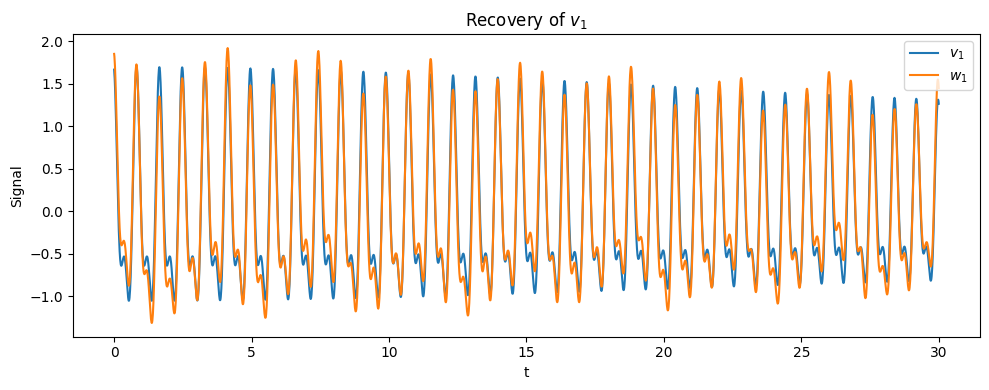

In [151]:
plt.figure(figsize=(10, 4))
plt.plot(t, v_1, label=r"$v_1$")
plt.plot(t, w_1, label=r"$w_1$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v_1$")
plt.legend()
plt.tight_layout()
plt.show()

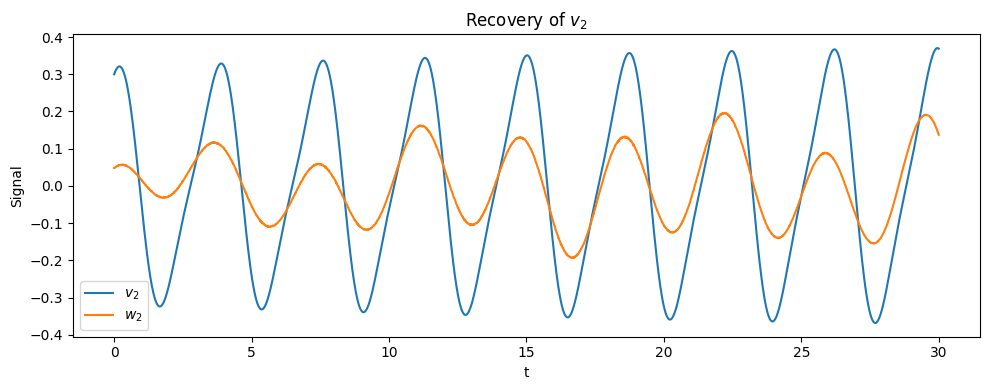

In [152]:
plt.figure(figsize=(10, 4))
plt.plot(t, v_2, label=r"$v_2$")
plt.plot(t, w_2, label=r"$w_2$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v_2$")
plt.legend()
plt.tight_layout()
plt.show()

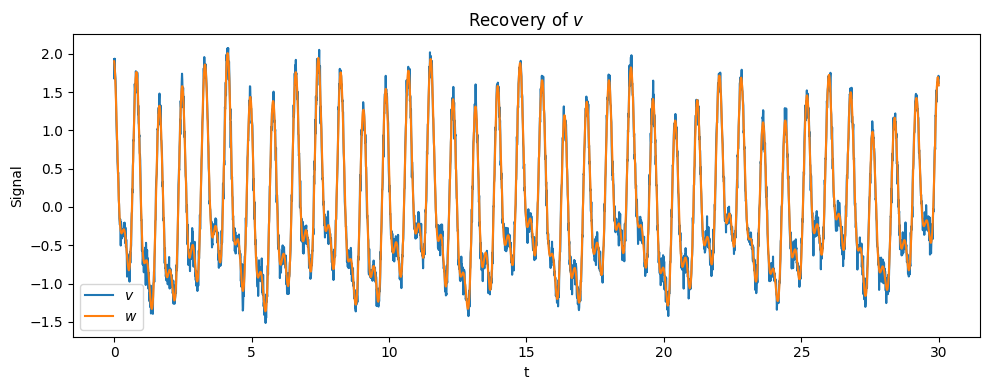

In [153]:
plt.figure(figsize=(10, 4))
plt.plot(t, v, label=r"$v$")
plt.plot(t, w, label=r"$w$")

plt.xlabel("t")
plt.ylabel("Signal")
plt.title(r"Recovery of $v$")
plt.legend()
plt.tight_layout()
plt.show()

In [154]:
from torch.utils.data import TensorDataset, DataLoader

def make_windows(x, L, H):
    X, Y = [], []
    for i in range(len(x) - L - H + 1):
        X.append(x[i:i+L])
        Y.append(x[i+L:i+L+H])
    return torch.stack(X), torch.stack(Y)

class LinearForecaster(nn.Module):
    def __init__(self, L, H):
        super().__init__()
        self.linear = nn.Linear(L, H)

    def forward(self, x):
        return self.linear(x)

def train_model(x_train, L=400, H=50, epochs=200, lr=1e-3, batch_size=64):
    X, Y = make_windows(x_train, L, H)
    ds = TensorDataset(X, Y)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=True)

    model = LinearForecaster(L, H)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()

    for epoch in range(epochs):
        for xb, yb in dl:
            pred = model(xb)
            loss = loss_fn(pred, yb)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model

def rolling_forecast(model, x, L, H):
    preds = []
    trues = []
    starts = []

    for i in range(len(x) - L - H + 1):
        x_in = x[i:i+L].unsqueeze(0)
        y_true = x[i+L:i+L+H]
        with torch.no_grad():
            y_pred = model(x_in).squeeze(0)
        preds.append(y_pred)
        trues.append(y_true)
        starts.append(i)

    return torch.stack(preds), torch.stack(trues), starts

def rmse(pred, true):
    return torch.sqrt(torch.mean((pred - true)**2))

def mae(pred, true):
    return torch.mean(torch.abs(pred - true))

n = len(v)
n_train = int(0.7 * n)
n_val = int(0.85 * n)

v_train, v_test = v[:n_train], v[n_val:]
w_train, w_test = w[:n_train], w[n_val:]
w1_train, w1_test = w_1[:n_train], w_1[n_val:]
w2_train, w2_test = w_2[:n_train], w_2[n_val:]
clean_train, clean_test = (v_1+v_2)[:n_train], (v_1+v_2)[n_val:]

L = 400
H = 50

model_v  = train_model(v_train,  L=L, H=H)
model_w  = train_model(w_train,  L=L, H=H)
model_w1 = train_model(w1_train, L=L, H=H)
model_w2 = train_model(w2_train, L=L, H=H)

pred_v, true_v, _ = rolling_forecast(model_v, v_test, L, H)
pred_w, true_w, _ = rolling_forecast(model_w, w_test, L, H)
pred_w1, true_w1, _ = rolling_forecast(model_w1, w1_test, L, H)
pred_w2, true_w2, _ = rolling_forecast(model_w2, w2_test, L, H)

pred_modes = pred_w1 + pred_w2
true_modes = true_w1 + true_w2

print("Direct v forecast RMSE vs observed v:", rmse(pred_v, true_v))
print("Direct w forecast RMSE vs reconstructed w:", rmse(pred_w, true_w))
print("Mode-sum forecast RMSE vs reconstructed w:", rmse(pred_modes, true_modes))

Direct v forecast RMSE vs observed v: tensor(0.1382)
Direct w forecast RMSE vs reconstructed w: tensor(0.0770)
Mode-sum forecast RMSE vs reconstructed w: tensor(0.1023)


In [155]:

from torch.distributions.multivariate_normal import MultivariateNormal

# =========================================================
# Simulate truth on [0, 35]
# =========================================================
T_train = 30.0
T_future = 35.0
dt = 0.01

N_full = int(T_future / dt + 1)
t_full = torch.linspace(0.0, T_future, N_full)

a_1_full = 1.0 + 0.15 * torch.cos(0.08 * t_full)
a_2_full = 0.3 + 0.05 * torch.sin(0.04 * t_full)

omega_1_full = 2 * torch.pi * (1.2 + 0.08 * torch.sin(0.03 * t_full))
omega_2_full = 2 * torch.pi * (0.25 + 0.02 * torch.cos(0.02 * t_full))

theta_1_full = 2 * torch.pi * (1.2 * t_full - 0.08 / 0.03 * torch.cos(0.03 * t_full) + 0.08 / 0.03)
theta_2_full = 2 * torch.pi * (0.25 * t_full + torch.sin(0.02 * t_full))

def y_1(s):
    return torch.cos(s) + 0.45 * torch.cos(2 * s) - 0.2 * torch.sin(2 * s)

def y_2(s):
    return torch.cos(s) + 0.2 * torch.sin(2 * s)

v_1_full = a_1_full * y_1(theta_1_full)
v_2_full = a_2_full * y_2(theta_2_full)

noise_sigma = 0.1
mvn_full = MultivariateNormal(torch.zeros(N_full), noise_sigma**2 * torch.eye(N_full))
noise_full = mvn_full.sample()

v_full = v_1_full + v_2_full + noise_full

# =========================================================
# Training region [0,30]
# =========================================================
N_train = int(T_train / dt + 1)

t = t_full[:N_train]
v = v_full[:N_train]
v_1 = v_1_full[:N_train]
v_2 = v_2_full[:N_train]

# Ground-truth future on (30,35]
future_slice = slice(N_train, N_full)
t_future = t_full[future_slice]
v_future_true = v_full[future_slice]
v_future_noiseless = (v_1_full+v_2_full)[future_slice]
v1_future_true = v_1_full[future_slice]
v2_future_true = v_2_full[future_slice]

In [156]:
def make_one_step_data(x, L=3):
    X, y = [], []
    for i in range(len(x) - L):
        X.append(x[i:i+L])
        y.append(x[i+L])
    return torch.stack(X), torch.stack(y)

def pairwise_sqdist(X1, X2):
    x1_norm = (X1**2).sum(dim=1, keepdim=True)
    x2_norm = (X2**2).sum(dim=1, keepdim=True).T
    return x1_norm + x2_norm - 2 * (X1 @ X2.T)

def gaussian_gram(X1, X2, ell):
    D2 = pairwise_sqdist(X1, X2)
    return torch.exp(-D2 / (2 * ell**2))

def median_lengthscale(X, max_points=2000):
    if len(X) > max_points:
        idx = torch.randperm(len(X))[:max_points]
        Xs = X[idx]
    else:
        Xs = X
    D2 = pairwise_sqdist(Xs, Xs)
    D = torch.sqrt(torch.clamp(D2, min=0.0))
    vals = D[torch.triu(torch.ones_like(D, dtype=torch.bool), diagonal=1)]
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 1.0
    return torch.median(vals).item()

class KernelRepresenterForecaster:
    def __init__(self, L=3, ell=None, lam=1e-4, standardize=True):
        self.L = L
        self.ell = ell
        self.lam = lam
        self.standardize = standardize

        self.x_mean = None
        self.x_std = None
        self.X_train = None
        self.alpha = None

    def fit(self, x):
        X_train, y_train = make_one_step_data(x, L=self.L)

        if self.standardize:
            self.x_mean = x.mean()
            self.x_std = x.std()
            if self.x_std < 1e-8:
                self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)
            X_train = (X_train - self.x_mean) / self.x_std
            y_train = (y_train - self.x_mean) / self.x_std
        else:
            self.x_mean = torch.tensor(0.0, dtype=x.dtype, device=x.device)
            self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)

        if self.ell is None:
            self.ell = median_lengthscale(X_train)

        K = gaussian_gram(X_train, X_train, self.ell)
        n = len(X_train)
        K_reg = K + self.lam * torch.eye(n, dtype=K.dtype, device=K.device)

        self.X_train = X_train
        self.alpha = torch.linalg.solve(K_reg, y_train)

    def predict_next(self, x_window):
        xq = x_window.clone()
        if self.standardize:
            xq = (xq - self.x_mean) / self.x_std

        kq = gaussian_gram(xq.unsqueeze(0), self.X_train, self.ell).squeeze(0)
        yq = torch.dot(kq, self.alpha)

        if self.standardize:
            yq = yq * self.x_std + self.x_mean
        return yq

    def recursive_forecast(self, x_history, horizon_steps):
        history = x_history.clone()
        preds = []
        for _ in range(horizon_steps):
            x_window = history[-self.L:] 
            y_next = self.predict_next(x_window)
            preds.append(y_next)
            history = torch.cat([history, y_next.view(1)])
        return torch.stack(preds)

In [157]:
def rmse(x, y):
    return torch.sqrt(torch.mean((x - y)**2))

L = 1000
horizon_steps = len(v_future_true)

# 1) use w directly
model_w = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_w.fit(w)
pred_from_w = model_w.recursive_forecast(w, horizon_steps)

# 2) use v directly
model_v = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v.fit(v)
pred_from_v = model_v.recursive_forecast(v, horizon_steps)

# 3) use true v1, v2 separately and sum
model_v1 = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v2 = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v1.fit(v_1)
model_v2.fit(v_2)
pred_v1 = model_v1.recursive_forecast(v_1, horizon_steps)
pred_v2 = model_v2.recursive_forecast(v_2, horizon_steps)
pred_from_true_modes = pred_v1 + pred_v2

# 4) use recovered w1, w2 separately and sum
model_w1 = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_w2 = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_w1.fit(w_1)
model_w2.fit(w_2)
pred_w1 = model_w1.recursive_forecast(w_1, horizon_steps)
pred_w2 = model_w2.recursive_forecast(w_2, horizon_steps)
pred_from_recovered_modes = pred_w1 + pred_w2

print("RMSE route 1: using w directly, scored vs future v =", rmse(pred_from_w, v_future_true))
print("RMSE route 2: using v directly, scored vs future v =", rmse(pred_from_v, v_future_true))
print("RMSE route 3: using true v1,v2 and summing, scored vs future v =", rmse(pred_from_true_modes, v_future_true))
print("RMSE route 4: using recovered w1,w2 and summing, scored vs future v =", rmse(pred_from_recovered_modes, v_future_true))

print("lengthscales:",
      model_w.ell, model_v.ell, model_v1.ell, model_v2.ell, model_w1.ell, model_w2.ell)

RMSE route 1: using w directly, scored vs future v = tensor(0.1183)
RMSE route 2: using v directly, scored vs future v = tensor(0.1490)
RMSE route 3: using true v1,v2 and summing, scored vs future v = tensor(0.1049)
RMSE route 4: using recovered w1,w2 and summing, scored vs future v = tensor(0.2284)
lengthscales: 47.760704040527344 47.688941955566406 48.036216735839844 45.25497817993164 47.86705017089844 44.581050872802734


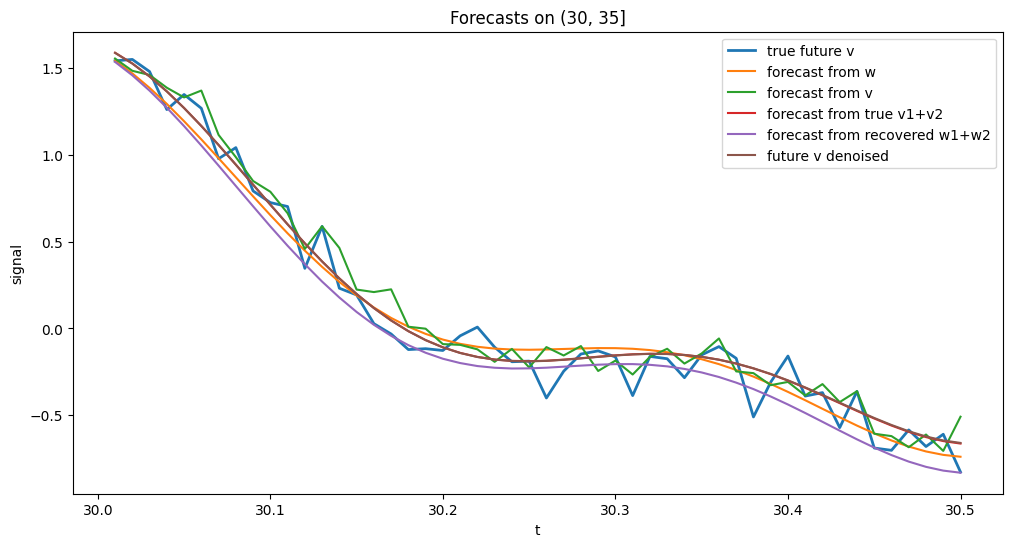

In [158]:
h= 50

plt.figure(figsize=(12, 6))
plt.plot(t_future.numpy()[:h], v_future_true.numpy()[:h], label="true future v", linewidth=2)
plt.plot(t_future.numpy()[:h],pred_from_w[:h], label="forecast from w")
plt.plot(t_future.numpy()[:h], pred_from_v[:h], label="forecast from v")
plt.plot(t_future.numpy()[:h], pred_from_true_modes[:h], label="forecast from true v1+v2")
plt.plot(t_future.numpy()[:h], pred_from_recovered_modes[:h], label="forecast from recovered w1+w2")
plt.plot(t_future.numpy()[:h], v_future_noiseless[:h], label="future v denoised")
plt.legend()
plt.xlabel("t")
plt.ylabel("signal")
plt.title("Forecasts on (30, 35]")
plt.show()

In [30]:
torch.min(pred_from_true_modes[:h]-v_future_noiseless[:h])

tensor(-0.0038)

In [168]:
fg = torch.randn(3,2,2)

In [169]:
fg.reshape(-1,2,2).shape

torch.Size([3, 2, 2])

In [167]:
fg.shape

torch.Size([3, 2, 2])